In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

In [3]:
from scripts_.stitching_vk_data import plot_stitched_height_image_from_vk #, plot_stitched_height_image_from_vk_2
from scripts_.tilt_correction import baseplane_filter
from scripts_.plot_vk_data import plot_vk4_height, plot_vk4_reflected_light, reshape_img_data
from scripts_.plot_csv_data import plot_csv_height
from scripts_.load_vk_data import parse_vk6_file, parse_vk4_file
from scripts_.preprocess_vk_data import crop_Vk4File_map
from scripts_.feature_enhancement import feature_enhancement_proceedings, feature_enhancement_1, feature_enhancement_2, feature_enhancement_3
#from scripts_.vk_height_to_csv import vk_height_to_csv

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

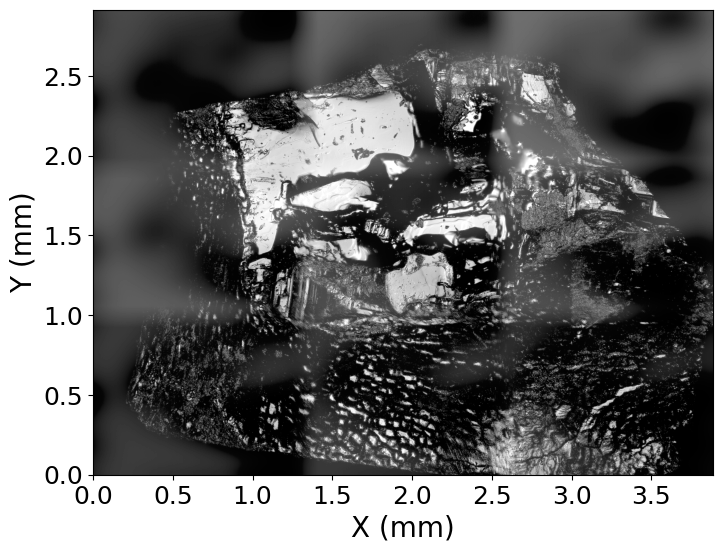

In [10]:
file_name = Path("../all_raw_data_vk/Sample 3 Milan/Side 2/Stitched 10x.vk4")

with open(file_name, 'rb') as f:
    data_vk4 = parse_vk4_file(f)

ax = plot_vk4_reflected_light(data_vk4)
plt.plot()
plt.savefig('NaCl sample 3 side 2 marked areas.jpeg')

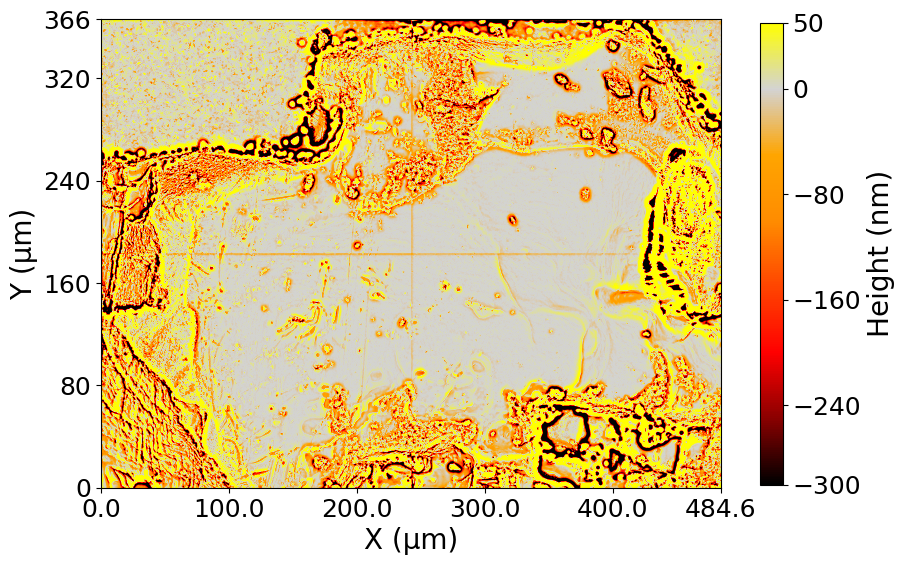

In [14]:
ax = plot_stitched_height_image_from_vk(Path("../all_raw_data_vk/Sample 3 Milan/Side 2/Stitched 50x the different flat region/20260625174759_Y*_X*.vk4"), 'feat_enhanced')

In [10]:
ax = plot_stitched_height_image_from_vk(Path("../all_raw_data_vk/Sample 3 Milan/Side 2/Stitched 50x flat region/20260618115549_Y*_X*.vk4"), 'feat_enhanced')

ValueError: No tiles found. Files processed: []

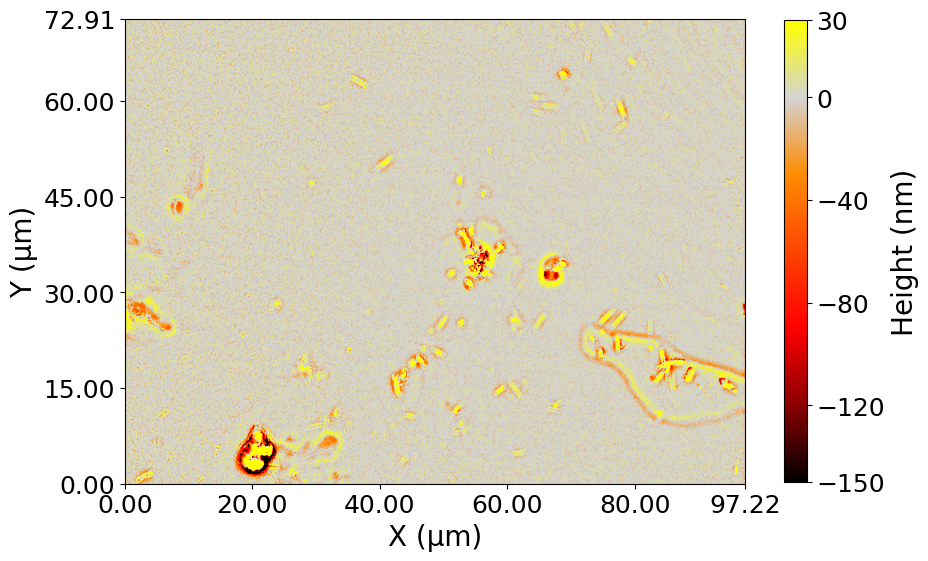

In [26]:
file_name_2 = Path("../all_raw_data_vk/Sample 3 Milan/Side 2/Single 150x the different flat region.vk6")

data_2_vk6 = parse_vk6_file(file_name_2)   
data_2_vk4 = parse_vk4_file(data_2_vk6['Vk4File'])
data_vk4_tiltcorr = baseplane_filter(data_2_vk4, 100)
data_vk4_enhanced = feature_enhancement_1(data_vk4_tiltcorr)

ax = plot_vk4_height(data_vk4_enhanced, data_type='feature_enhanced')

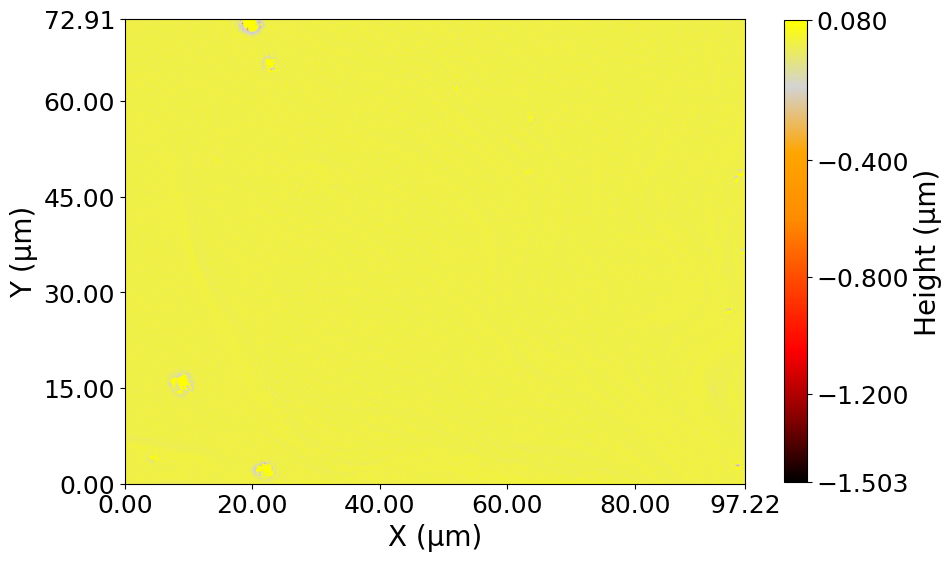

In [11]:
file_name_2 = Path("../all_raw_data_vk/Sample 3 Milan/Side 2/Single 2 150x the different flat region.vk6")

data_2_vk6 = parse_vk6_file(file_name_2)   
data_2_vk4 = parse_vk4_file(data_2_vk6['Vk4File'])
data_vk4_tiltcorr = baseplane_filter(data_2_vk4, 100)
data_vk4_enhanced = feature_enhancement_1(data_vk4_tiltcorr)

ax = plot_vk4_height(data_vk4_enhanced, data_type='feature_enhanced')

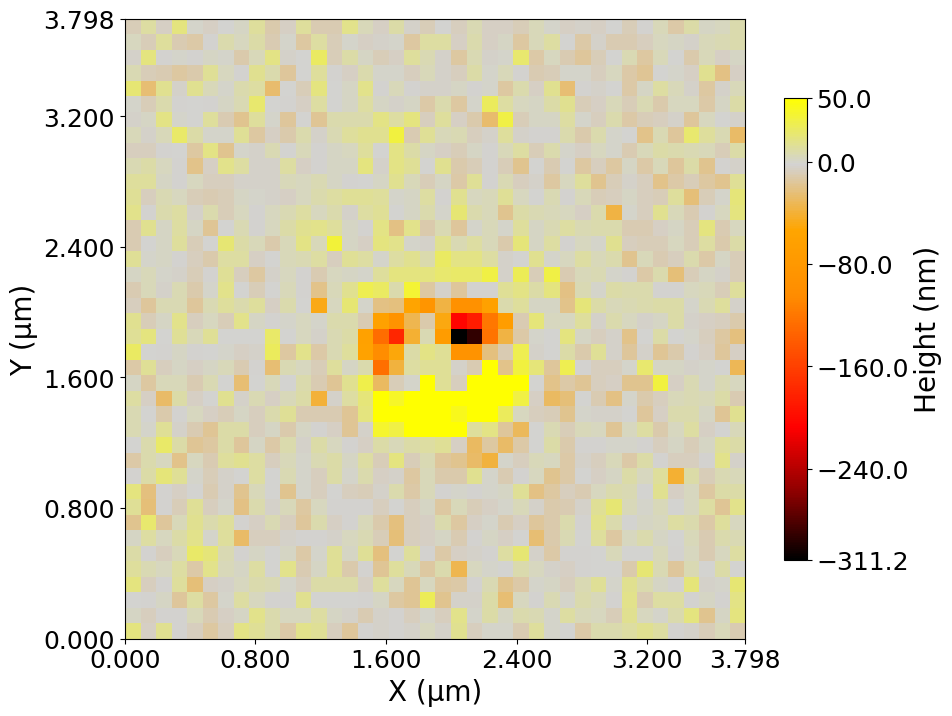

In [7]:
cropped = crop_Vk4File_map(data_vk4_enhanced, x0=975, x1=1015, y0=460, y1=500)
ax = plot_vk4_height(cropped, data_type='feature_enhanced')

[[-0.00437807  0.01401755 -0.00252707 ... -0.00217344 -0.00054472
   0.00394508]
 [ 0.00748637 -0.00413233  0.01430879 ...  0.00032812  0.00196341
   0.00346004]
 [-0.00061458  0.0217532   0.00018092 ... -0.00012897 -0.00848715
  -0.00198364]
 ...
 [ 0.00258359  0.00070494  0.00485867 ...  0.00246109 -0.00218289
   0.01703991]
 [ 0.0059741  -0.00290997  0.00023712 ... -0.01717039  0.0022153
   0.01846762]
 [ 0.02142816 -0.00246234  0.0176771  ... -0.00770475  0.00471212
  -0.01000467]]


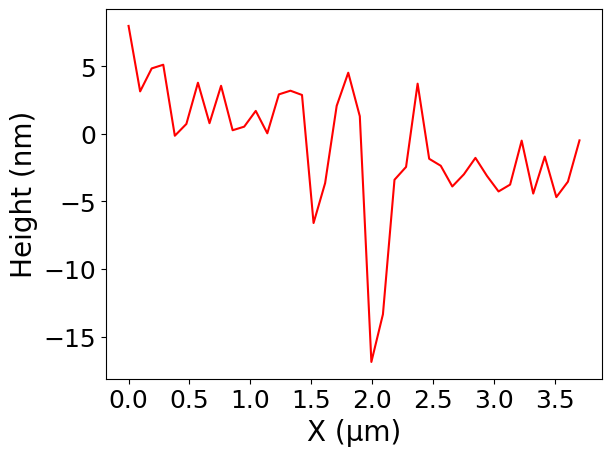

In [30]:
reshaped = reshape_img_data(cropped, data_type='feature_enhanced')
profile_baseplane = np.mean(reshaped, axis=0)*1000
x_pixels = reshaped.shape[1]
print(reshaped)
x_um = np.arange(x_pixels) * 0.094938
plt.plot(x_um, profile_baseplane, 'red')

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

#plt.xlim()

plt.xlabel('X (µm)', fontsize=20)
plt.ylabel('Height (nm)', fontsize=20)

plt.show()

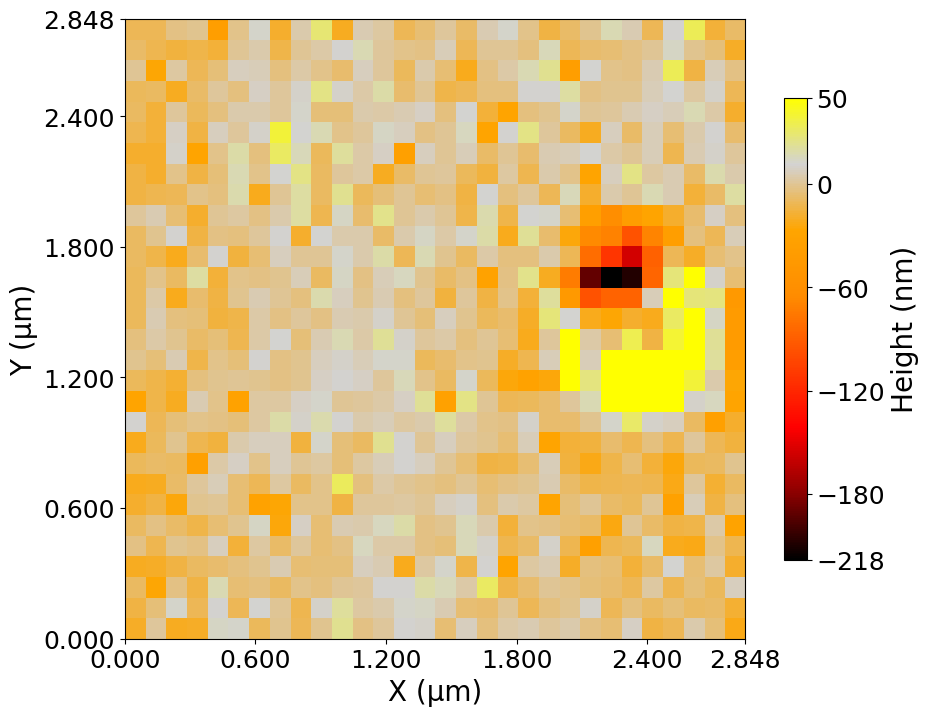

In [9]:
cropped = crop_Vk4File_map(data_vk4_enhanced, x0=994, x1=1024, y0=370, y1=400)
ax = plot_vk4_height(cropped, data_type='feature_enhanced')

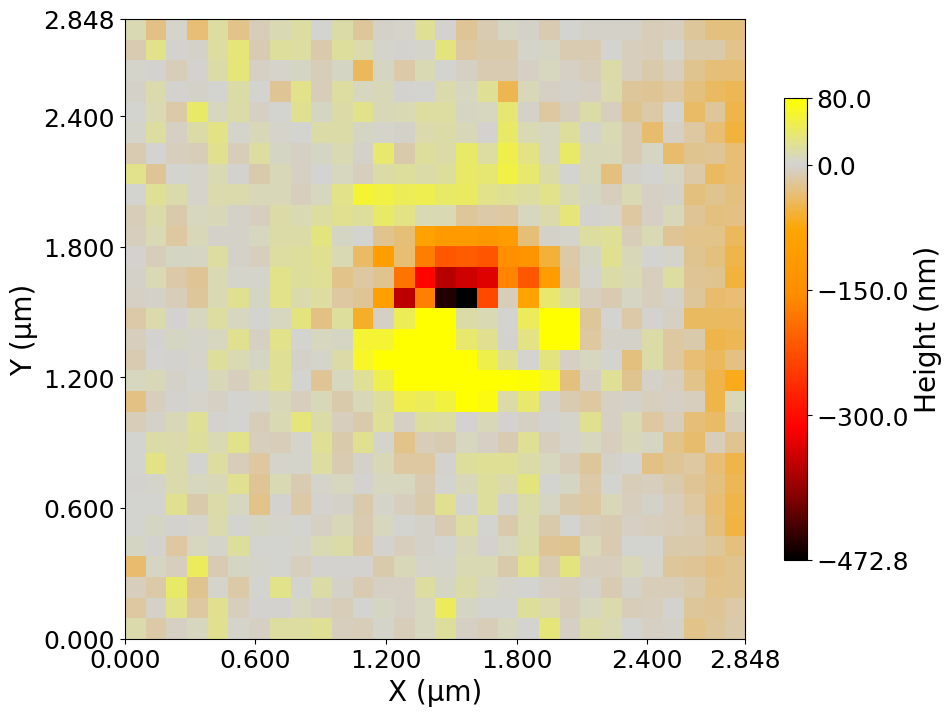

In [12]:
cropped = crop_Vk4File_map(data_vk4_enhanced, x0=994, x1=1024, y0=725, y1=755)
ax = plot_vk4_height(cropped, data_type='feature_enhanced')

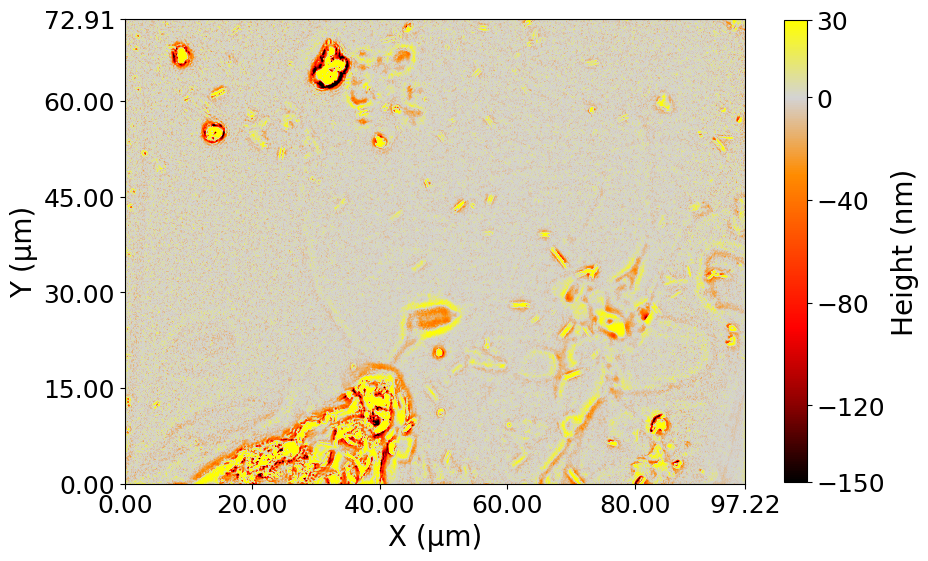

In [28]:
file_name_2 = Path("../all_raw_data_vk/Sample 3 Milan/Side 2/Single 3 150x the different flat region.vk6")

data_2_vk6 = parse_vk6_file(file_name_2)   
data_2_vk4 = parse_vk4_file(data_2_vk6['Vk4File'])
data_vk4_tiltcorr = baseplane_filter(data_2_vk4, 100)
data_vk4_enhanced = feature_enhancement_1(data_vk4_tiltcorr)

ax = plot_vk4_height(data_vk4_enhanced, data_type='feature_enhanced')